In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append('../../code')
from utils import simulate_single_server_queue_from_times
from tqdm import tqdm

<div dir="rtl">

## חישובים בסיסיים

## נעשה סימולציה עם זמנים בין הגעות ושירות המגיעים מן ההתפלגויות הבאות:

### $$ A\sim U(0.5, 1.5) $$
### $$ S\sim exp(1.25) $$

<div dir="rtl">

## נגריל ונראה ממוצעים וסטיות תקן

In [3]:
n = 500000
inter_arrival_times = np.random.uniform(0.5,1.5,n)
service_times = np.random.exponential(1/1.25, n)

inter_arrival_times.mean(), service_times.mean()

(np.float64(0.9995314425444904), np.float64(0.7988878825396464))

In [36]:
inter_arrival_times.std(), service_times.std()

(np.float64(0.2886327156589557), np.float64(0.7977770105994011))

<div dir="rtl">

###  נעשה סימולציה שתחזיר לנו:

#### 1. waiting_times - זמני המתנה
#### 2. sojourn_times - זמני שהייה
#### 3. queuae_length_distribution - התפגלות אורך תור
#### 4. number_in_system_distribution - התפלגות מספר צרכניםפ במערכת כלומר תור  + שירות

In [6]:
waiting_times, sojourn_times, queuae_length_distribution, number_in_system_distribution = simulate_single_server_queue_from_times(
    inter_arrival_times=inter_arrival_times,
    service_times=service_times)



<div dir="rtl">

### נציג התפלגות זמני שהייה

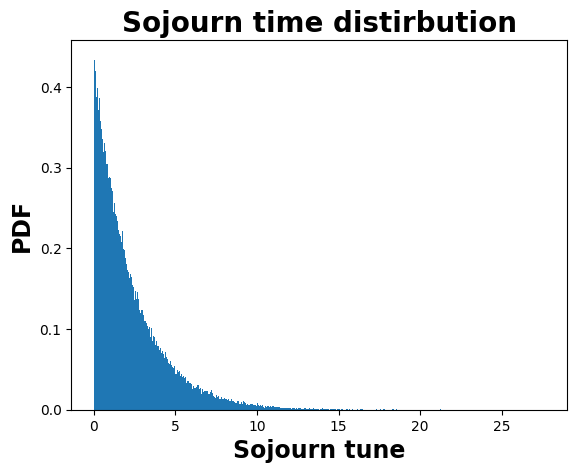

In [8]:
plt.figure()
plt.hist(sojourn_times, density = True, bins = 2500)
plt.title('Sojourn time distirbution', fontsize = 20,  fontweight = 'bold')
plt.ylabel('PDF', fontsize = 17,  fontweight = 'bold')
plt.xlabel('Sojourn tune', fontsize = 17,  fontweight = 'bold')
plt.show()

<div dir="rtl">

## נגיד נרצה לחשב את ההסתברות שזמני השהייה יהיו בין 2 ל-4 דקות.

### כלומר השטח הכחול בין הקווים השחורים

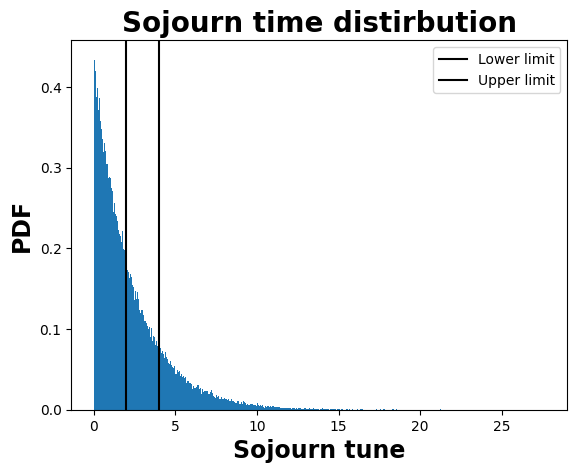

In [10]:
plt.figure()
plt.hist(sojourn_times, density = True, bins = 2500)
plt.title('Sojourn time distirbution', fontsize = 20,  fontweight = 'bold')
plt.ylabel('PDF', fontsize = 17,  fontweight = 'bold')
plt.xlabel('Sojourn tune', fontsize = 17,  fontweight = 'bold')
plt.axvline(2, color='black',  label='Lower limit')
plt.axvline(4, color='black',  label='Upper limit')
plt.legend()
plt.show()



<div dir="rtl">

### נחשב כך: 

In [11]:
((sojourn_times>2)&(sojourn_times<4)).mean()

np.float64(0.243986)

<div dir="rtl">

## כלומר פרופורציות זמני השהייה שהם בין 2 ל-4. 

### מה ההסתברות של שאורך התור יהיה בדיוק 0? 

In [37]:
queue_length_distribution[0]

np.float64(0.47814940979354337)

<div dir="rtl">

## מה הקשר בין התפלגות אורך התור למספר הצרכנים במערכת? 

### נשים לב שכאשר ההסתברות שיהיו בבמערכת 0 או 1 זה שני מקרים בהם אורך התור הוא בדיוק 0 ולכן:

In [26]:
number_in_system_distribution[0]+ number_in_system_distribution[1]

np.float64(0.47814940979354337)

In [38]:
queue_length_distribution[0]

np.float64(0.47814940979354337)

In [39]:
number_in_system_distribution[0]+ number_in_system_distribution[1] == queue_length_distribution[0]

np.True_

<div dir="rtl">

## נציג התפלגות מספר הצרכנים במערכת:

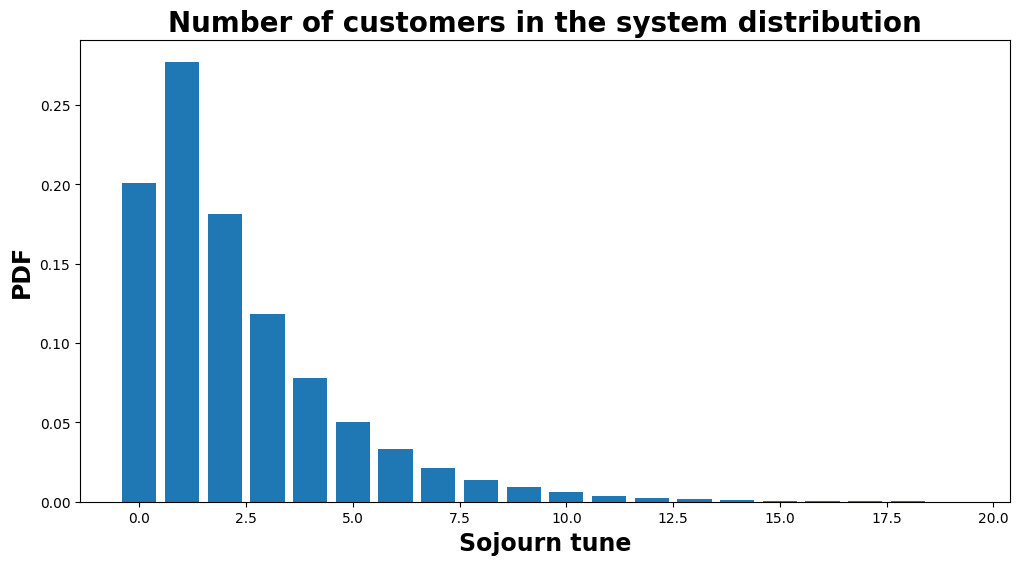

In [24]:
import numpy as np
import matplotlib.pyplot as plt

num_to_present = 20
x = np.arange(num_to_present)
y = number_in_system_distribution[:num_to_present]

plt.figure(figsize = (12,6))
plt.bar(x, y)
plt.title('Number of customers in the system distribution', fontsize = 20,  fontweight = 'bold')
plt.ylabel('PDF', fontsize = 17,  fontweight = 'bold')
plt.xlabel('Sojourn tune', fontsize = 17,  fontweight = 'bold')
plt.show()

<div dir="rtl">

## הסתברות שיהיו 10 צרכנים ומעלה במערכת.

In [25]:
number_in_system_distribution[10:].sum()

np.float64(0.0161508123101837)

<div dir="rtl">

## נחשב תוחלת לפי:

### $$ E[X]= \sum_i x_i p(x_i)  $$

### למטה חישוב של תוחלת אורך תור ומספר צרכנים במערכת:

In [30]:
(np.arange(number_in_system_distribution.shape[0])*number_in_system_distribution.mean()).sum(), (np.arange(queue_length_distribution.shape[0])*queue_length_distribution.mean()).sum()

(np.float64(13.5), np.float64(13.0))

<div dir="rtl">

### נחשב שונות של אורך תור ומספר צרכנים במערכת

### $$ Var[X] =  E[X^2] - E[X]^2 $$

## ניתן גם לסמן מומנטים לפי: 

### $$ m_i $$ עבור המומנט ה-$i$

### $$ Var[X] =  m_2 - m_1^2 $$

In [40]:
m1 = (np.arange(number_in_system_distribution.shape[0])*number_in_system_distribution.mean()).sum()
m2 =  ((np.arange(number_in_system_distribution.shape[0])**2)*(number_in_system_distribution).mean()).sum() 

var = m2-m1**2
std = var**0.5
var, std

(np.float64(65.25000000000003), np.float64(8.077747210701757))